| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../19_SOFTWARE_CIENTIFICO/19_1_SOFTWARE_CIENTIFICO.ipynb) | [⏩](../20_INVESTIGACION/20_2_Reproducir_papers.ipynb) |

# 20.1 CÓMO LEER PAPERS DE SCIENTIFIC MACHINE LEARNING

Leer un paper consiste en reconstruir una afirmación, sus supuestos y la evidencia que la sostiene. El objetivo es poder explicar **qué problema resuelve**, **cómo lo resuelve** y **hasta dónde permiten concluir sus experimentos**. No hace falta entender cada línea en la primera lectura.

Usaremos como ejemplo el trabajo de Raissi, Perdikaris y Karniadakis sobre Physics-Informed Neural Networks. La fuente primaria es [el manuscrito de los autores](https://arxiv.org/abs/1711.10561). El paper desarrolla aprendizaje para ecuaciones diferenciales; aquí construiremos una demostración reducida con una ODE y una base polinómica. **Es un experimento pedagógico inspirado en la idea de residual físico; no reproduce sus arquitecturas, datasets ni resultados publicados.**

**Objetivos.** Leer por capas, traducir ecuaciones a un experimento verificable y distinguir resultados, interpretaciones e hipótesis. Bibliotecas: NumPy y Matplotlib. Requisitos: mínimos cuadrados y ODE.

## 1. Primera lectura: pregunta y afirmación

Antes de mirar detalles, identifica el problema, las entradas y las salidas. ¿Se conoce la ecuación? ¿Se quieren estados, parámetros o ambas cosas? ¿Las observaciones son escasas o ruidosas? ¿Qué método sirve como referencia? Escribe una frase propia que describa el aporte.

Para la idea que estudiaremos: añadir un residual de la ecuación a una pérdida puede incorporar información sobre comportamientos que los datos no observan directamente. Eso no garantiza que cualquier ponderación mejore resultados ni que una pérdida pequeña implique exactitud global.

## 2. Segunda lectura: reconstruir la matemática

Para una ecuación $u_t+\mathcal N[u]=0$, una aproximación $u_\theta$ genera residual $r_\theta=u_{\theta,t}+\mathcal N[u_\theta]$. Una pérdida puede combinar
$$J(\theta)=J_{\text{datos}}+\lambda_fJ_{\text{física}}+\lambda_bJ_{\text{frontera}}.$$
Debemos comprobar cómo se calculan derivadas, dónde se evalúan residuos, cómo se imponen condiciones y cómo se normaliza cada término. Sumar muchos puntos sin normalización cambia la escala del objetivo.

Para entender una ecuación, define cada símbolo y sus unidades. Distingue parámetro físico, parámetro de red e hiperparámetro. Si una derivada automática se usa para evaluar residual, pregunta si la red es suficientemente suave para la PDE que se quiere resolver.

## 3. Tercera lectura: evidencia y comparaciones

Busca métricas, referencias numéricas, particiones de datos, semillas y costos. Una figura visualmente convincente puede ocultar errores en fronteras o gradientes. Una reducción de error en una ecuación no demuestra generalización a todas las PDEs.

Una tabla comparativa debe usar condiciones equivalentes: resolución, presupuesto, datos, tolerancias y precisión de referencia. Una ablation elimina una parte del método para identificar su efecto. «Funciona en este experimento» y «funciona siempre» son afirmaciones de alcance distinto.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(201)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
T, k_real, sigma = 2.0, 0.65, 0.05
t_train = np.sort(rng.uniform(0.1, T, 10))
y_train = np.exp(-k_real*t_train)+rng.normal(0, sigma, len(t_train))
t_val = np.linspace(0.03, 1.97, 61)
y_val_limpio = np.exp(-k_real*t_val)
t_test = np.linspace(0, T, 501)
u_test = np.exp(-k_real*t_test)
print("Entrenamiento: 10 observaciones; validación y prueba sintéticas sin ruido.")

Entrenamiento: 10 observaciones; validación y prueba sintéticas sin ruido.


## 4. Un ejemplo mínimo que podemos comprobar

La ODE es $u'+ku=0$, $u(0)=1$, con solución $e^{-kt}$. Sustituiremos la red por
$$u_c(t)=1+\sum_{j=1}^d c_j (t/T)^j.$$
La condición inicial se satisface exactamente porque todos los términos desaparecen en $t=0$. La derivada de cada base es $\phi'_j(t)=j(t/T)^{j-1}/T$; incluir $1/T$ es esencial.

Ajustaremos
$$J(c)=\frac1{N_d}\|\Phi_dc-(y-1)\|^2+\frac{\lambda}{N_f}\|(\Phi'_f+k\Phi_f)c+k\mathbf1\|^2.$$
Es un problema lineal de mínimos cuadrados, que permite aislar el efecto de la penalización física sin confundirlo con dificultades de optimización de una red. También tiene limitaciones de aproximación polinómica.

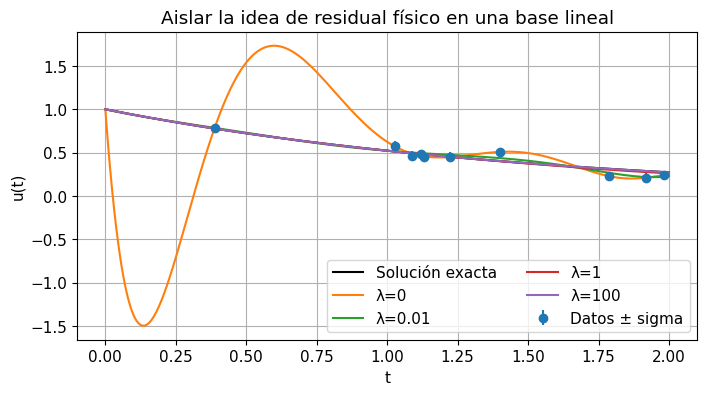

In [2]:
def bases(t, grado=7):
    t = np.asarray(t); s = t/T; potencias = np.arange(1, grado+1)
    phi = s[:, None]**potencias[None, :]
    dphi = potencias[None, :]/T*s[:, None]**(potencias[None, :]-1)
    return phi, dphi

def ajustar(lam, k_modelo=k_real, n_col=60, grado=7):
    phi_d, _ = bases(t_train, grado)
    tf = np.linspace(0, T, n_col)
    phi_f, dphi_f = bases(tf, grado)
    A_d = phi_d/np.sqrt(len(t_train))
    b_d = (y_train-1)/np.sqrt(len(t_train))
    A_f = np.sqrt(lam/n_col)*(dphi_f+k_modelo*phi_f)
    b_f = -np.sqrt(lam/n_col)*k_modelo*np.ones(n_col)
    coef, *_ = np.linalg.lstsq(np.vstack([A_d, A_f]), np.r_[b_d, b_f], rcond=None)
    return coef

def evaluar(t, coef):
    phi, dphi = bases(t, len(coef))
    return 1+phi @ coef, dphi @ coef

fig, ax = plt.subplots()
ax.plot(t_test, u_test, "k", label="Solución exacta")
ax.errorbar(t_train, y_train, yerr=sigma, fmt="o", label="Datos ± sigma")
for lam in [0, 0.01, 1, 100]:
    pred, _ = evaluar(t_test, ajustar(lam))
    ax.plot(t_test, pred, label=f"λ={lam}")
ax.set(xlabel="t", ylabel="u(t)", title="Aislar la idea de residual físico en una base lineal")
ax.legend(ncol=2); plt.show()

## 5. Separar la pérdida de la métrica de interés

El objetivo de entrenamiento es una combinación de términos. La métrica científica puede ser error relativo de solución, gradiente, conservación o predicción de una cantidad de interés. Un valor de $J$ no se compara entre distintos $\lambda$ como si fuera la misma métrica: su definición ha cambiado.

Calcularemos MSE de datos, MSE de residual en una malla densa y error de solución en validación. La validación limpia es posible aquí por disponer de solución exacta; en un problema real usaríamos datos no usados para ajustar o una referencia de mayor precisión.

Seleccionar $\lambda$ por validación utiliza información. Por eso la prueba final debe mantenerse separada y no convertirse en otra fuente de selección repetida.

λ elegido por validación: 1000.0


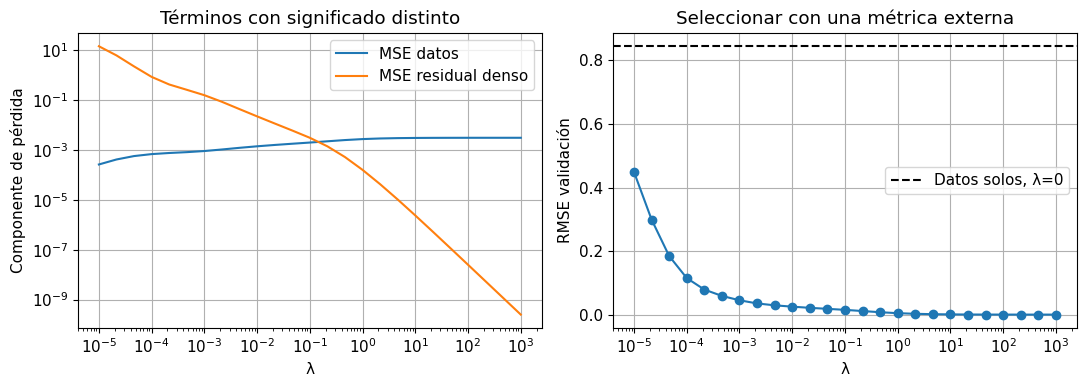

In [3]:
lambdas = np.r_[0.0, np.logspace(-5, 3, 25)]
J_datos, J_fisica, E_val = [], [], []
for lam in lambdas:
    coef = ajustar(lam)
    ud, _ = evaluar(t_train, coef)
    uv, _ = evaluar(t_val, coef)
    up, dup = evaluar(t_test, coef)
    J_datos.append(np.mean((ud-y_train)**2))
    J_fisica.append(np.mean((dup+k_real*up)**2))
    E_val.append(np.sqrt(np.mean((uv-y_val_limpio)**2)))
idx = int(np.argmin(E_val)); lambda_elegido = float(lambdas[idx])
print("λ elegido por validación:", lambda_elegido)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# λ=0 se informa por separado porque no cabe en el eje logarítmico.
axes[0].loglog(lambdas[1:], J_datos[1:], label="MSE datos")
axes[0].loglog(lambdas[1:], J_fisica[1:], label="MSE residual denso")
axes[0].set(xlabel="λ", ylabel="Componente de pérdida", title="Términos con significado distinto"); axes[0].legend()
axes[1].semilogx(lambdas[1:], E_val[1:], "o-")
axes[1].axhline(E_val[0], color="k", ls="--", label="Datos solos, λ=0")
axes[1].set(xlabel="λ", ylabel="RMSE validación", title="Seleccionar con una métrica externa")
axes[1].legend(); plt.tight_layout(); plt.show()

## 6. Residual pequeño: ¿dónde se midió?

La pérdida física se evalúa en un conjunto finito de puntos. Un modelo flexible puede tener residual bajo allí y alto entre puntos. Esto es análogo al sobreajuste de datos y depende de regularidad, distribución de colocación y clase de aproximación.

Mediremos residual tanto en colocación como en una malla densa para distintos números de puntos. Nuestro ejemplo lineal y polinómico tiene complejidad controlada; no pretende caracterizar todas las PINNs. La comparación muestra cómo una decisión aparentemente secundaria del paper se convierte en una hipótesis concreta.

Nf=4: RMSE residual colocación=0.00181, denso=0.1109
Nf=8: RMSE residual colocación=0.01321, denso=0.01505
Nf=20: RMSE residual colocación=0.01262, denso=0.01293
Nf=60: RMSE residual colocación=0.0125, denso=0.01258


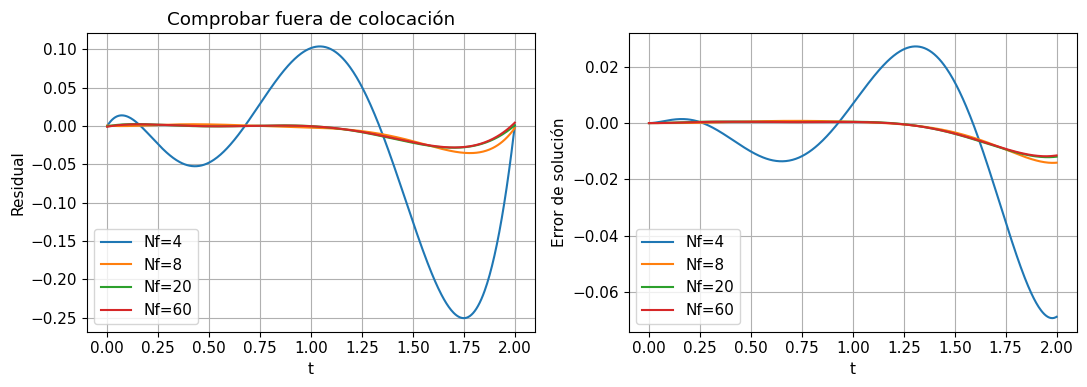

In [4]:
ncols = [4, 8, 20, 60]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nc in ncols:
    cc = ajustar(1.0, n_col=nc)
    up, dup = evaluar(t_test, cc)
    tf = np.linspace(0, T, nc); uf, duf = evaluar(tf, cc)
    residual_denso = dup+k_real*up
    print(f"Nf={nc}: RMSE residual colocación={np.sqrt(np.mean((duf+k_real*uf)**2)):.4g}, denso={np.sqrt(np.mean(residual_denso**2)):.4g}")
    axes[0].plot(t_test, residual_denso, label=f"Nf={nc}")
    axes[1].plot(t_test, up-u_test, label=f"Nf={nc}")
axes[0].set(xlabel="t", ylabel="Residual", title="Comprobar fuera de colocación")
axes[1].set(xlabel="t", ylabel="Error de solución")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 7. Supuestos físicos: si la ecuación es incorrecta

Una pérdida física solo es útil si la ecuación y sus parámetros son adecuados. Si imponemos $k=0.95$ cuando los datos fueron generados con $k=0.65$, una penalización fuerte obliga al ajuste a acercarse a una dinámica equivocada.

Esto no refuta el enfoque de información física: identifica un supuesto necesario y su efecto. Al leer un paper, busca si se estudió ruido, parámetros erróneos, discrepancia de modelo o condiciones nuevas. Si no se estudiaron, el resultado no permite concluir robustez frente a esos escenarios.

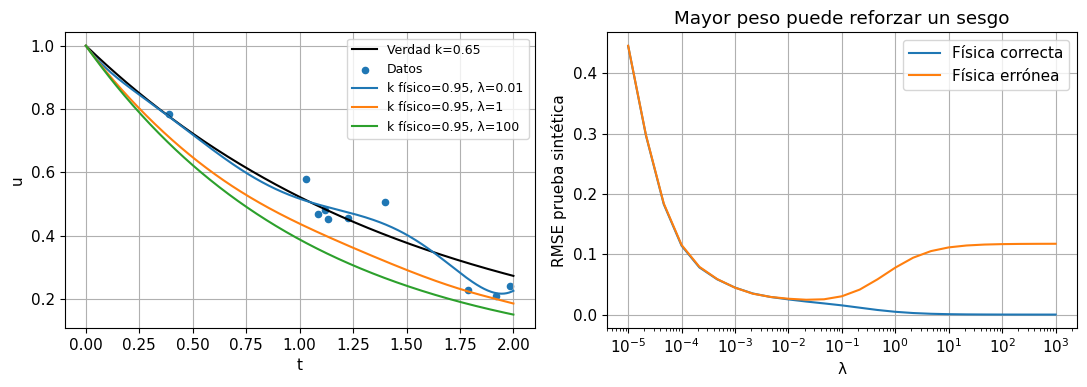

In [5]:
k_erroneo = 0.95
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t_test, u_test, "k", label="Verdad k=0.65")
axes[0].scatter(t_train, y_train, s=20, label="Datos")
error_correcto, error_erroneo = [], []
for lam in lambdas[1:]:
    pc, _ = evaluar(t_test, ajustar(lam, k_modelo=k_real))
    pe, _ = evaluar(t_test, ajustar(lam, k_modelo=k_erroneo))
    error_correcto.append(np.sqrt(np.mean((pc-u_test)**2)))
    error_erroneo.append(np.sqrt(np.mean((pe-u_test)**2)))
for lam in [0.01, 1, 100]:
    pe, _ = evaluar(t_test, ajustar(lam, k_modelo=k_erroneo))
    axes[0].plot(t_test, pe, label=f"k físico=0.95, λ={lam}")
axes[0].set(xlabel="t", ylabel="u"); axes[0].legend(fontsize=9)
axes[1].semilogx(lambdas[1:], error_correcto, label="Física correcta")
axes[1].semilogx(lambdas[1:], error_erroneo, label="Física errónea")
axes[1].set(xlabel="λ", ylabel="RMSE prueba sintética", title="Mayor peso puede reforzar un sesgo")
axes[1].legend(); plt.tight_layout(); plt.show()

## 8. Ablation y controles positivos/negativos

La comparación $\lambda=0$ frente a $\lambda>0$ elimina la información física y constituye una ablation del ejemplo. El modelo con física correcta es un control positivo; el modelo con parámetro erróneo es un control que revela límites. Otra ablation podría cambiar condición inicial impuesta exactamente por una penalización blanda.

Para atribuir una diferencia a un componente, hay que mantener datos, clase de aproximación y evaluación. Si se cambia simultáneamente arquitectura, número de épocas y dataset, no se puede aislar el efecto de la física.

## 9. Leer figuras con preguntas concretas

Para cada figura identifica ejes, unidades, normalización, barras de error y selección de casos. Pregunta si muestra entrenamiento o prueba, un promedio o una semilla, una cantidad local o global. Busca escalas que oculten colas o errores pequeños.

Una figura de solución superpuesta necesita complementarse con errores. Una figura de pérdida necesita una métrica externa. Una curva de velocidad debe decir qué incluye el tiempo. El objetivo es convertir la lectura en una afirmación verificable, no en una impresión visual.

## 10. Elaborar una ficha de lectura

Registra referencia y versión; pregunta científica; supuestos físicos; entradas y salidas; ecuaciones clave; método de optimización; datasets y partición; métricas; comparadores; resultados que puedes verificar; límites y preguntas abiertas. Escribe las conclusiones con tus propias palabras y vincula cada una a una figura o experimento.

Distingue «los autores reportan» de «yo comprobé». En este cuaderno comprobamos una idea en una ODE y base polinómica. No hemos reproducido los experimentos PDE del trabajo original ni medido el rendimiento de sus redes.

## 11. Del paper al código

Una implementación requiere decisiones que el texto puede omitir: normalización, precisión, distribución de colocación, criterio de parada y semilla. Antes de rellenar esas lagunas con intuición, revisa apéndices y código de los autores si están disponibles. Documenta las decisiones propias.

Empieza por un caso pequeño con referencia exacta y después escala. Si un método falla incluso en el caso reducido, revisa ecuaciones, derivadas y pérdidas antes de invertir en hardware. Si funciona, todavía queda comprobar que el mecanismo se conserva en el problema publicado.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../19_SOFTWARE_CIENTIFICO/19_1_SOFTWARE_CIENTIFICO.ipynb) | [⏩](../20_INVESTIGACION/20_2_Reproducir_papers.ipynb) |